# Parte 5 — Simulación de ciclo de vida y criterios de retiro

**Objetivo:** definir qué se monitorea en producción, con qué umbrales, y qué se hace
cuando se cruzan.

> ⚠️ **Simulación sintética.** Home Credit no tiene dimensión temporal, así que los "meses"
> se construyen a partir del test set con dos mecanismos explícitos. Los resultados muestran
> cómo reaccionan las métricas de monitoreo; no son una predicción de lo que pasaría en
> producción.

**Escenario simulado (mes m = 0…12):**
1. **Cambio en el mix de solicitantes:** cada mes la cartera se re-muestrea dándole más peso
   a solicitantes jóvenes y con score de bureau bajo (p. ej. una campaña comercial agresiva
   o la salida de competidores). Los defaults son los reales de esos clientes.
2. **Inflación no indexada:** ingresos y montos nominales crecen 3% mensual y el modelo no se
   re-entrena. En términos reales nada cambia, pero el modelo ve clientes "más ricos".

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from src.config import reference_cutoff
from src.models.pd_model import PDScorer
from src.validation.model_validation import compute_psi

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

CUTOFF   = reference_cutoff()
scorer   = PDScorer()
X_train  = pd.read_parquet('data/processed/X_train.parquet')
raw_test = pd.read_parquet('data/processed/test.parquet')
pd_ref   = scorer.pd_from_features(X_train)      # distribución de referencia (desarrollo)

## 5.1 Simulación mensual

In [2]:
rng = np.random.default_rng(7)
N_MES = 20_000
INFLACION_MENSUAL = 0.03
BETA_MIX = 0.06          # intensidad del cambio de mix por mes

# índice de "riesgo de mix": joven y con bureau bajo (estandarizado)
ext = raw_test[['EXT_SOURCE_2', 'EXT_SOURCE_3']].mean(axis=1).fillna(raw_test['EXT_SOURCE_2'].median())
z = (-(raw_test['age_years'] - raw_test['age_years'].mean()) / raw_test['age_years'].std()
     - (ext - ext.mean()) / ext.std()).values

def simular_mes(m):
    w = np.exp(BETA_MIX * m * z); w /= w.sum()
    idx = rng.choice(len(raw_test), N_MES, replace=True, p=w)
    d = raw_test.iloc[idx].reset_index(drop=True).copy()
    infl = (1 + INFLACION_MENSUAL) ** m
    for c in ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']:
        d[c] = d[c] * infl
    return d

gini_0 = None
filas = []
for m in range(13):
    d  = simular_mes(m)
    p  = scorer.pd_from_raw(d)
    y  = d['default'].values
    g  = 2 * roc_auc_score(y, p) - 1
    gini_0 = gini_0 or g
    ap = p < CUTOFF
    gm = d['CODE_GENDER'].isin(['M', 'F']).values
    rates = pd.Series(ap[gm]).groupby(d['CODE_GENDER'].values[gm]).mean()
    filas.append({
        'mes': m, 'gini': g, 'psi_score': compute_psi(pd_ref, p),
        'pd_media': p.mean(), 'default_real': y.mean(),
        'citl_rel': (p.mean() - y.mean()) / y.mean(),
        'aprobacion': ap.mean(), 'mora_aprobados': y[ap].mean(),
        'dir_genero': rates.min() / rates.max(),
    })
sim = pd.DataFrame(filas).set_index('mes')
sim.round(4)

,gini,psi_score,pd_media,default_real,citl_rel,aprobacion,mora_aprobados,dir_genero
mes,,,,,,,,
0,0.5086,0.0014,0.0784,0.0795,-0.0128,0.9298,0.0630,0.9540
1,0.5039,0.0006,0.0792,0.0872,-0.0921,0.9276,0.0717,0.9560
2,0.5042,0.0078,0.0845,0.0930,-0.0907,0.9194,0.0728,0.9563
3,0.5213,0.0253,0.0901,0.0974,-0.0752,0.9060,0.0736,0.9438
4,0.4995,0.0565,0.0970,0.1014,-0.0437,0.8839,0.0763,0.9338
5,0.5118,0.1003,0.1031,0.1066,-0.0329,0.8700,0.0760,0.9363
6,0.5046,0.1426,0.1083,0.1112,-0.0260,0.8554,0.0790,0.9245
7,0.5047,0.1974,0.1146,0.1198,-0.0428,0.8404,0.0834,0.9315
8,0.5032,0.2758,0.1215,0.1246,-0.0257,0.8199,0.0838,0.9142


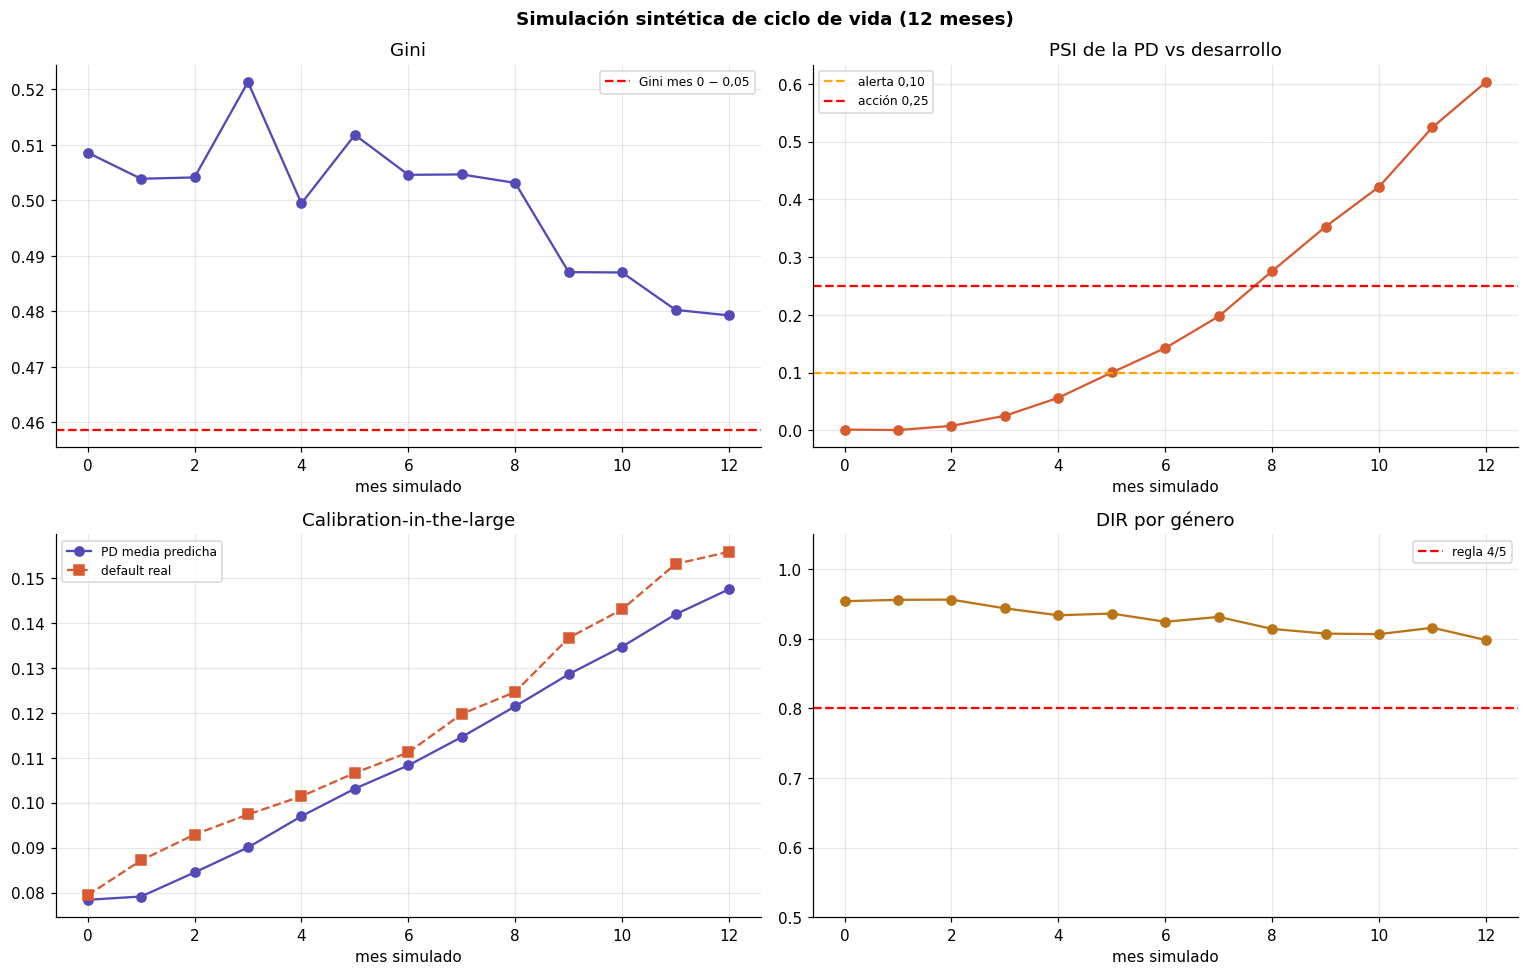

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.ravel()
axes[0].plot(sim.index, sim['gini'], 'o-', color='#534AB7'); axes[0].axhline(gini_0 - 0.05, color='red', ls='--', label='Gini mes 0 − 0,05')
axes[0].set_title('Gini')
axes[1].plot(sim.index, sim['psi_score'], 'o-', color='#D85A30')
axes[1].axhline(0.10, color='orange', ls='--', label='alerta 0,10'); axes[1].axhline(0.25, color='red', ls='--', label='acción 0,25')
axes[1].set_title('PSI de la PD vs desarrollo')
axes[2].plot(sim.index, sim['pd_media'], 'o-', color='#534AB7', label='PD media predicha')
axes[2].plot(sim.index, sim['default_real'], 's--', color='#D85A30', label='default real')
axes[2].set_title('Calibration-in-the-large')
axes[3].plot(sim.index, sim['dir_genero'], 'o-', color='#BA7517'); axes[3].axhline(0.80, color='red', ls='--', label='regla 4/5')
axes[3].set_title('DIR por género'); axes[3].set_ylim(0.5, 1.05)
for ax in axes:
    ax.set_xlabel('mes simulado'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.suptitle('Simulación sintética de ciclo de vida (12 meses)', fontweight='bold')
plt.tight_layout(); plt.savefig('reports/figures/lifecycle_simulation.png', dpi=150, bbox_inches='tight'); plt.show()

## 5.2 Cruces de umbral

In [4]:
umbrales = {
    'Gini (caída > 0,05)':          sim['gini'] < gini_0 - 0.05,
    'PSI > 0,10 (alerta)':          sim['psi_score'] > 0.10,
    'PSI > 0,25 (acción)':          sim['psi_score'] > 0.25,
    '|CITL| > 10% (calibración)':   sim['citl_rel'].abs() > 0.10,
    'DIR género < 0,80':            sim['dir_genero'] < 0.80,
}
for nombre, cond in umbrales.items():
    meses = cond[cond].index.tolist()
    print(f'{nombre:<30} ' + (f'primer cruce en mes {meses[0]}' if meses else 'no cruza en 12 meses'))

Gini (caída > 0,05)            no cruza en 12 meses
PSI > 0,10 (alerta)            primer cruce en mes 5
PSI > 0,25 (acción)            primer cruce en mes 8
|CITL| > 10% (calibración)     no cruza en 12 meses
DIR género < 0,80              no cruza en 12 meses


## 5.3 Lectura y criterios de retiro

**Qué muestra la simulación.**
- **El Gini es lo último que se mueve:** pasa de 0,51 a 0,48 en 12 meses y nunca cruza el
  umbral de −0,05. Además, en producción el Gini se observa con 12 meses de retraso (hay que
  esperar los defaults), así que no sirve como alarma temprana.
- **El PSI de la PD es la primera señal:** supera 0,10 en el mes 5 y 0,25 en el mes 8. Está
  disponible el mismo día de la originación.
- **La calibración se mueve antes que el Gini:**
  - el modelo subestima entre 3% y 9% todos los meses con el cambio de mix (la PD media queda
    debajo del default real);
  - no cruza el umbral de ±10%, pero la dirección es sistemática y es la peligrosa
    (provisiones insuficientes).
- **Fairness por género estable** (DIR 0,90–0,96).
- **La aprobación cae de 93% a 74%:** con el cutoff fijo, el modelo reacciona solo a la
  población más riesgosa. Es el comportamiento correcto, pero es un cambio de negocio que hay
  que explicar a la gerencia comercial.

### Criterios de monitoreo y retiro propuestos

| Métrica | Frecuencia | Alerta | Acción |
|---|---|---|---|
| PSI de la PD (vs desarrollo) | mensual | > 0,10 → investigar features que derivan | > 0,25 → comité de modelos: recalibrar o re-entrenar |
| Calibration-in-the-large (PD media vs default observado de la cosecha) | trimestral, con cosechas maduras | \|desvío\| > 10% | \|desvío\| > 20% o 2 trimestres seguidos subestimando → recalibrar |
| Backtest por grado (Jeffreys) | semestral | grado en ámbar | grado en rojo → recalibrar |
| Gini de cosechas maduras (12 meses) | semestral | caída > 0,05 | Gini < 0,40 → re-desarrollo |
| DIR por género y edad | mensual | < 0,85 | < 0,80 → revisión de fairness |

**Validación completa:** anual, o antes si se dispara cualquier "acción". Es coherente con el
enfoque de SR 26-2, que fija la frecuencia de validación según la materialidad y el riesgo
del modelo en lugar de un calendario fijo.